# Computer Vision Masterclass - Face detection

## OpenCV

### Loading the image

In [8]:
import cv2

librarary function of the opencv lib

# To import Drive into Colab

In [9]:
!unzip -q "/content/images.zip"

replace images/car.jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: None


In [10]:
!unzip -q "/content/cascade.zip"

replace cascade/cars.xml? [y]es, [n]o, [A]ll, [N]one, [r]ename: None


In [11]:
image = cv2.imread('/content/images/people1.jpg')

# To see Image Properties

In [12]:
image.shape

(1280, 1920, 3)

1280 -wide , 1920-high, 3 planes

In [13]:
#cv2.imshow(image)
from google.colab.patches import cv2_imshow
cv2_imshow(image)

Output hidden; open in https://colab.research.google.com to view.

In [14]:
image = cv2.resize(image, (800, 600))
image.shape

(600, 800, 3)

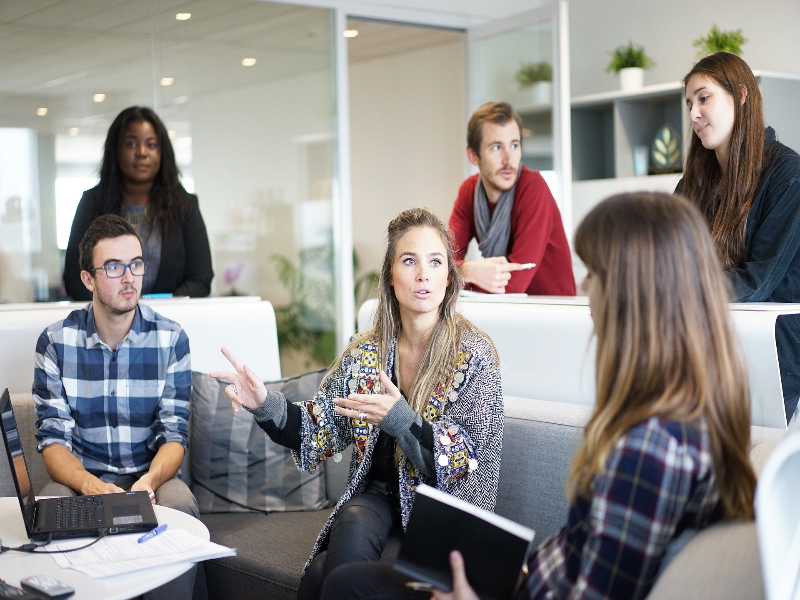

In [15]:
cv2_imshow(image)

In [16]:
600 * 800 * 3, 600 * 800, 1440000 - 480000

(1440000, 480000, 960000)

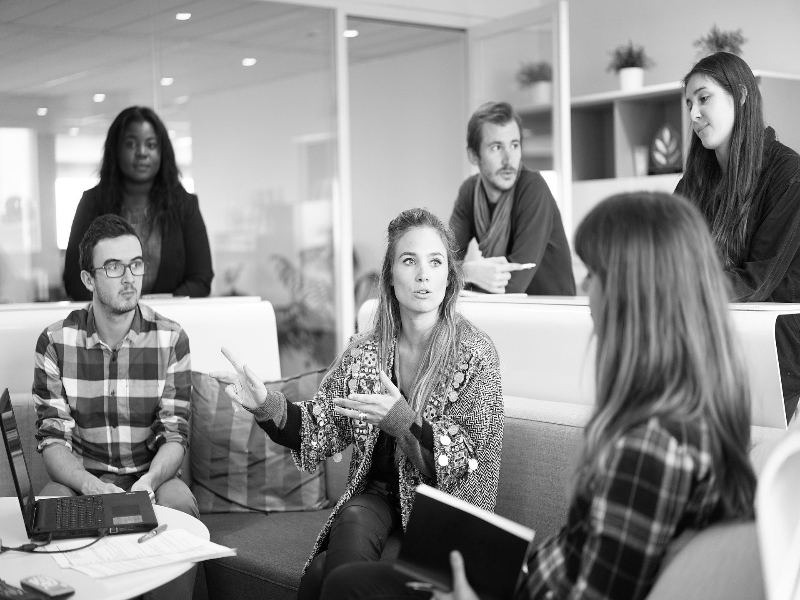

In [17]:
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
cv2_imshow(image_gray)

In [18]:
image.shape

(600, 800, 3)

In [19]:
image_gray.shape

(600, 800)

### Detecting faces

In [20]:
face_detector = cv2.CascadeClassifier('/content/cascade/haarcascade_frontalface_default.xml')

In [21]:
detections = face_detector.detectMultiScale(image_gray)

In [22]:
detections

array([[677,  72,  68,  68],
       [115, 124,  53,  53],
       [475, 123,  59,  59],
       [387, 233,  73,  73],
       [ 92, 239,  66,  66],
       [390, 323,  56,  56]], dtype=int32)

Each and every row represents the detection of individual face in the picture

In [23]:
len(detections)

6

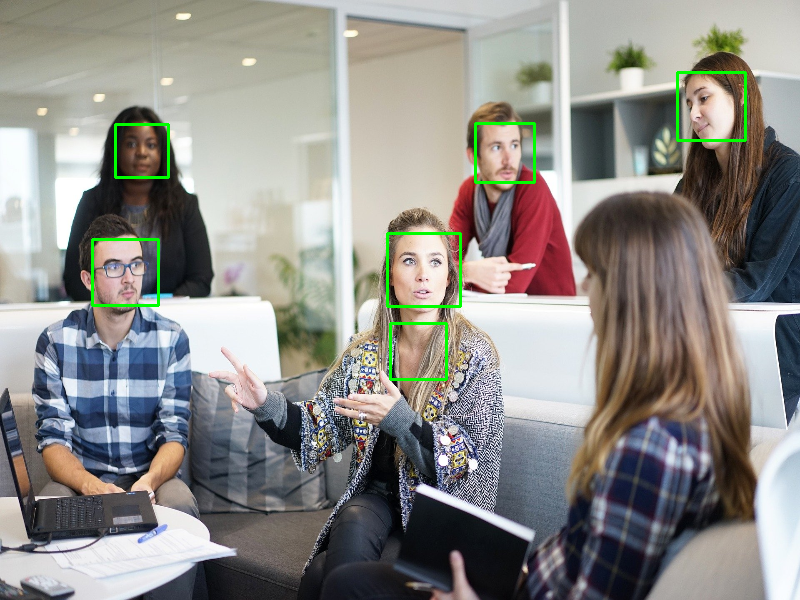

In [24]:
for (x, y, w, h) in detections:
  #print(x, y, w, h)
  cv2.rectangle(image, (x, y), (x + w, y + h), (0,255,0), 2)
cv2_imshow(image)

### Haarcascade parameters

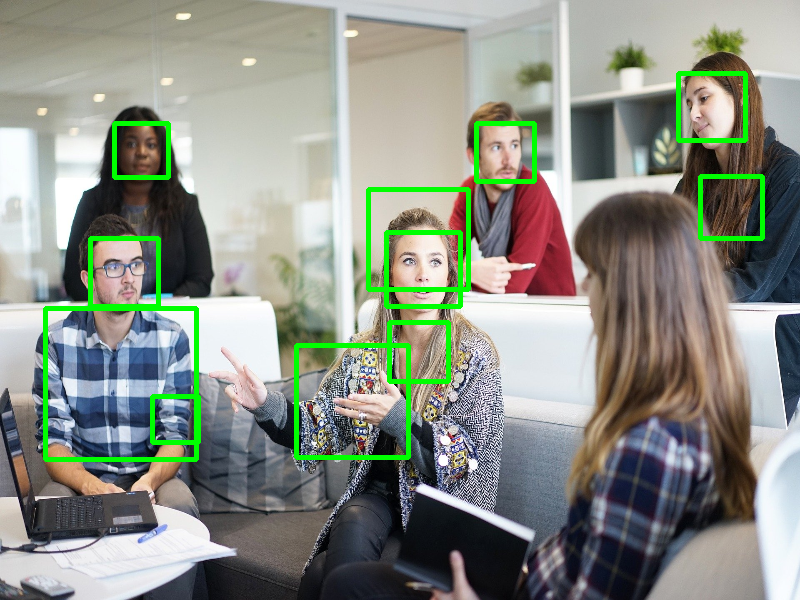

In [25]:
image = cv2.imread('/content/images/people1.jpg')
image = cv2.resize(image, (800,600))
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
detections = face_detector.detectMultiScale(image_gray, scaleFactor=1.01)
for (x, y, w, h) in detections:
  cv2.rectangle(image, (x, y), (x + w, y + h), (0,255,0), 3)
cv2_imshow(image)

scale factor - to scale the face of the image,
*small scale factor value when the image of the face are small
*default value 1.1

47 47
44 44
50 50
45 45
51 51
50 50
46 46
54 54
51 51
50 50
49 49
51 51
47 47
46 46
33 33


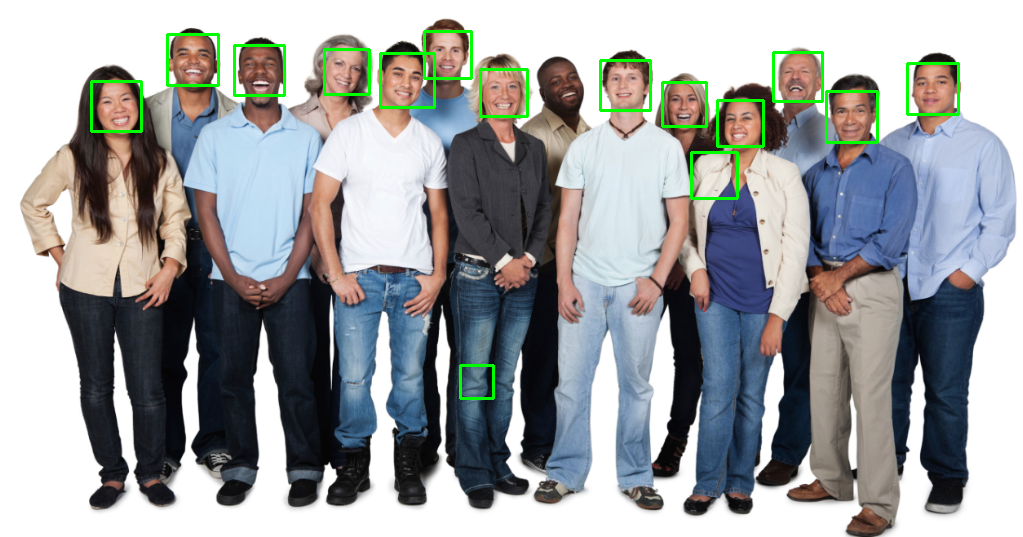

In [28]:
image = cv2.imread('/content/images/people2.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
detections = face_detector.detectMultiScale(image_gray, scaleFactor=1.05, minNeighbors=5,
                                            minSize=(30,30), maxSize=(100,100))
for (x, y, w, h) in detections:
  print(w, h)
  cv2.rectangle(image, (x, y), (x + w, y + h), (0,255,0), 2)
cv2_imshow(image)

min Neighbours represents number of rectangles needed to consider this as a final rectangle - higher the value is the higher the quality

### Eye detection

In [29]:
eye_detector = cv2.CascadeClassifier('/content/drive/MyDrive/Cascades/haarcascade_eye.xml')

In [59]:
image = cv2.imread('/content/images/people1.jpg')
#image = cv2.resize(image, (800, 600))
print(image.shape)
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# Initialize the eye detector using the correct local path
eye_detector = cv2.CascadeClassifier('/content/cascade/haarcascade_eye.xml')

face_detections = face_detector.detectMultiScale(image_gray, scaleFactor = 1.4, minSize = (30,30))
for (x, y, w, h) in face_detections:
  cv2.rectangle(image, (x, y), (x + w, y + h), (0,255,0), 2)

eye_detections = eye_detector.detectMultiScale(image_gray, scaleFactor = 1.05, minNeighbors=7, maxSize=(70,70))
for (x, y, w, h) in eye_detections:
  print(w, h)
  cv2.rectangle(image, (x, y), (x + w, y + h), (0,0,255), 2)

cv2_imshow(image)

Output hidden; open in https://colab.research.google.com to view.

### Other objects

#### Cars

21 21
21 21
28 28
30 30
36 36
42 42
23 23
24 24
24 24
40 40
42 42
26 26
24 24
26 26
24 24
29 29
36 36
40 40
42 42
20 20
22 22
35 35
29 29
44 44
42 42
22 22
40 40


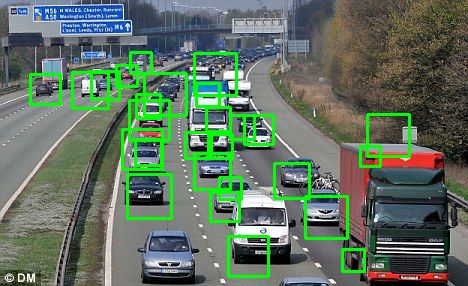

In [37]:
car_detector = cv2.CascadeClassifier('/content/cascade/cars.xml')
image = cv2.imread('/content/images/car.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
detections = car_detector.detectMultiScale(image_gray, scaleFactor = 1.01, minNeighbors=1,minSize=(5,5),maxSize=(45,45))
for (x, y, w, h) in detections:
  print(w,h)
  cv2.rectangle(image, (x, y), (x + w, y + h), (0,255,0), 2)
cv2_imshow(image)

#### Clocks

103 103
103 103
98 98
302 302
90 90
280 280
93 93
65 65
99 99


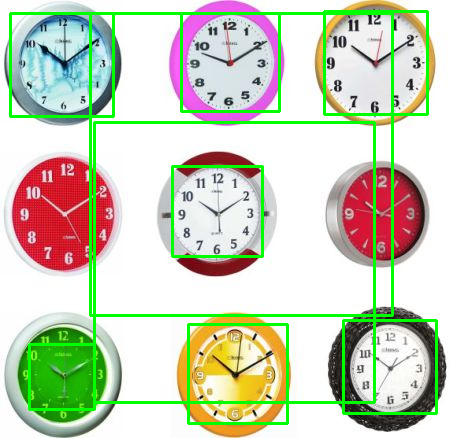

In [43]:
clock_detector = cv2.CascadeClassifier('/content/cascade/clocks.xml')
image = cv2.imread('/content/images/clock.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
detections = clock_detector.detectMultiScale(image_gray,scaleFactor=1.01,minNeighbors=1)
for (x, y, w, h) in detections:
  print(w,h)
  cv2.rectangle(image, (x, y), (x + w, y + h), (0,255,0), 2)
cv2_imshow(image)

#### Full body

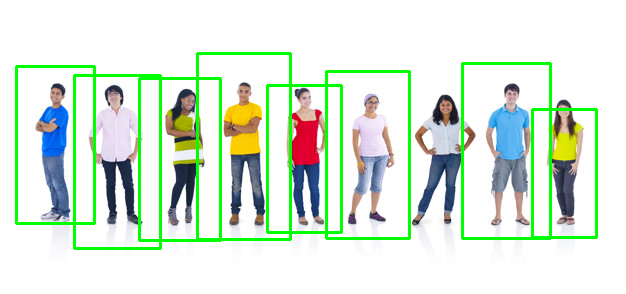

In [45]:
full_detector = cv2.CascadeClassifier('/content/cascade/fullbody.xml')
image = cv2.imread('/content/images/people3.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
detections = full_detector.detectMultiScale(image_gray, scaleFactor = 1.01, minNeighbors=5,
                                              minSize = (50,50))
for (x, y, w, h) in detections:
  cv2.rectangle(image, (x, y), (x + w, y + h), (0,255,0), 2)
cv2_imshow(image)

## Dlib

In [47]:
import dlib

### Detecting faces with HOG

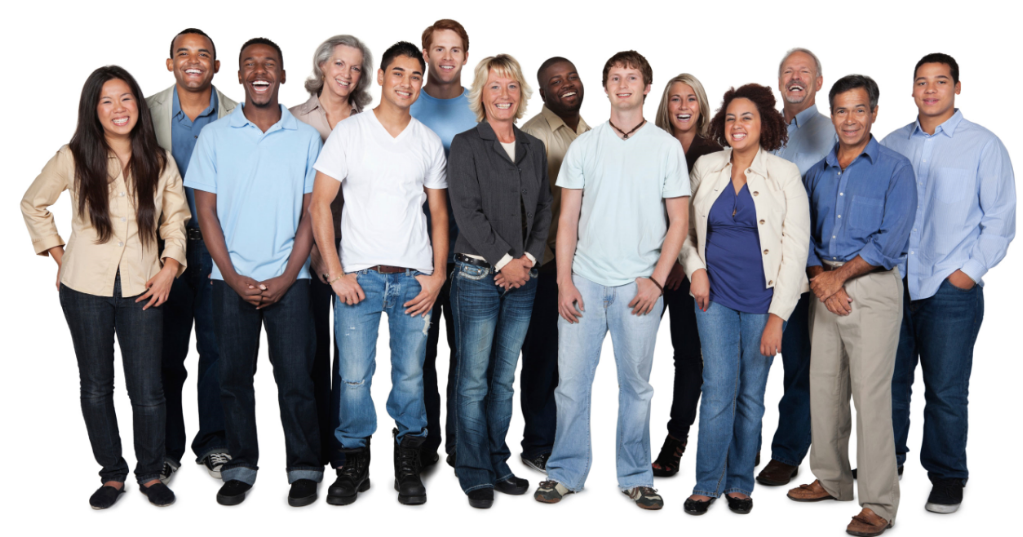

In [48]:
image = cv2.imread('/content/images/people2.jpg')
cv2_imshow(image)

In [49]:
face_detector_hog = dlib.get_frontal_face_detector()

In [50]:
detections = face_detector_hog(image, 1)

In [51]:
detections, len(detections)

(rectangles[[(429, 38) (465, 74)], [(665, 90) (701, 126)], [(717, 103) (760, 146)], [(909, 70) (952, 113)], [(828, 98) (871, 142)], [(605, 70) (641, 106)], [(777, 62) (813, 98)], [(485, 78) (521, 114)], [(386, 60) (429, 103)], [(170, 41) (213, 84)], [(93, 89) (136, 132)], [(237, 50) (280, 94)], [(323, 50) (367, 94)], [(544, 65) (588, 108)]],
 14)

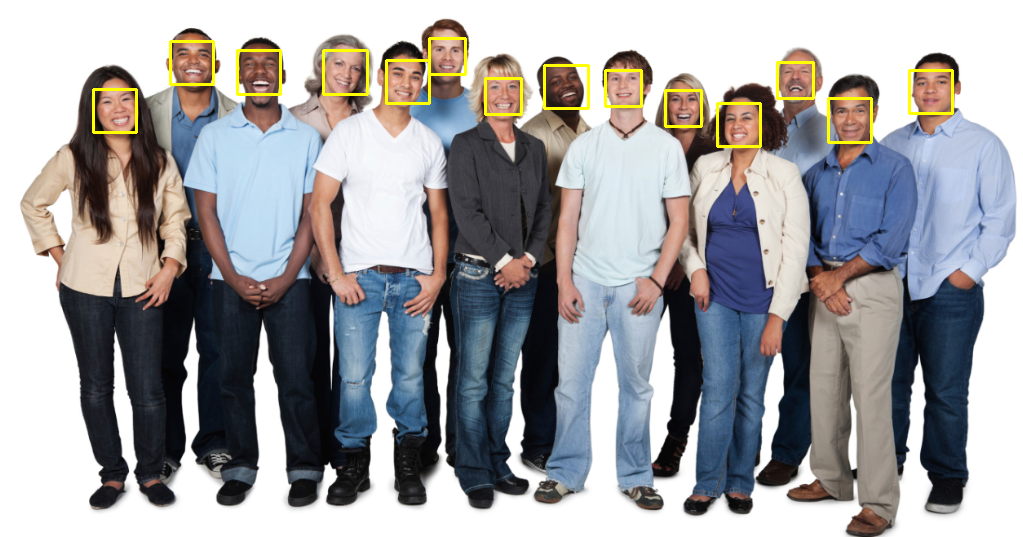

In [52]:
for face in detections:
  #print(face)
  #print(face.left())
  #print(face.top())
  #print(face.right())
  #print(face.bottom())
  l, t, r, b = face.left(), face.top(), face.right(), face.bottom()
  cv2.rectangle(image, (l, t), (r, b), (0, 255, 255), 2)
cv2_imshow(image)

### Detecting faces with CNN (Convolutional Neural Networks)

In [ ]:
image = cv2.imread('/content/images/people2.jpg')
cnn_detector = dlib.cnn_face_detection_model_v1('/content/drive/MyDrive/Cursos - recursos/Computer Vision Masterclass/Weights/mmod_human_face_detector.dat')

In [ ]:
detections = cnn_detector(image, 1)
for face in detections:
  l, t, r, b, c = face.rect.left(), face.rect.top(), face.rect.right(), face.rect.bottom(), face.confidence
  print(c)
  cv2.rectangle(image, (l, t), (r, b), (255, 255, 0), 2)
cv2_imshow(image)

### Haarcascade x HOG x CNN

#### Haarcascade

In [53]:
image.shape

(537, 1023, 3)

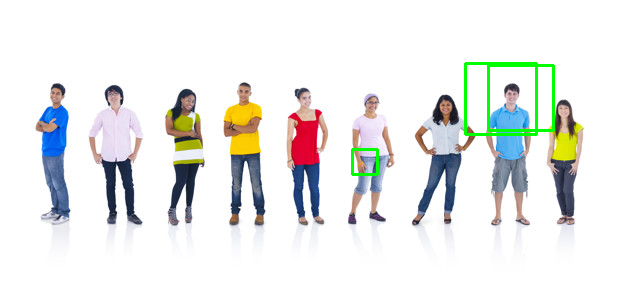

In [68]:
image = cv2.imread('/content/images/people3.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
haarcascade_detector = cv2.CascadeClassifier('/content/cascade/haarcascade_frontalface_default.xml')
detections = haarcascade_detector.detectMultiScale(image_gray, scaleFactor = 1.001, minNeighbors=1, minSize = (5,5))
for (x, y, w, h) in detections:
  cv2.rectangle(image, (x, y), (x + w, y + h), (0,255,0), 2)
cv2_imshow(image)

#### HOG

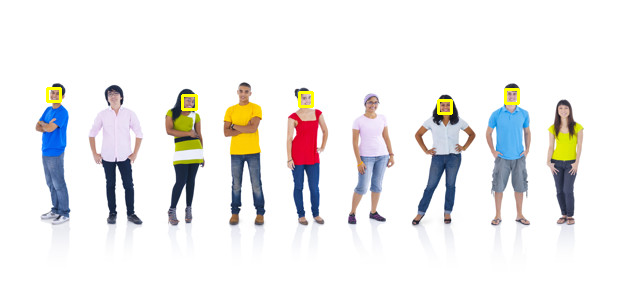

In [55]:
image = cv2.imread('/content/images/people3.jpg')
face_detector_hog = dlib.get_frontal_face_detector()
detections = face_detector_hog(image, 4)
for face in detections:
    l, t, r, b = (face.left(), face.top(), face.right(), face.bottom())
    cv2.rectangle(image, (l, t), (r, b), (0, 255, 255), 2)
cv2_imshow(image)

#### CNN

In [ ]:
image = cv2.imread('/content/images/people3.jpg')
cnn_detector = dlib.cnn_face_detection_model_v1('/content/drive/MyDrive/Cursos - recursos/Computer Vision Masterclass/Weights/mmod_human_face_detector.dat')
detections = cnn_detector(image, 4)
for face in detections:
  l, t, r, b, c = face.rect.left(), face.rect.top(), face.rect.right(), face.rect.bottom(), face.confidence
  print(c)
  cv2.rectangle(image, (l, t), (r, b), (255, 255, 0), 2)
cv2_imshow(image)